# Unit 2 – Linear Models for Regression and Classification

## Dataset: AI4Bharat LAHAJA

This notebook implements the Linear Models for Regression and Classification concepts covered in Unit 2.

The LAHAJA dataset contains Hindi speech data along with transcripts and speaker/demographic metadata. In this notebook, the available labeled metadata will be used to demonstrate regression and classification models.

In [ ]:
# Install required libraries
!pip -q install pyarrow scikit-learn pandas numpy matplotlib seaborn

In [ ]:
import pandas as pd
import numpy as np
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from pathlib import Path

data_dir = Path("/content/drive/MyDrive/LAHAJA")

print("LAHAJA folder:")
print(data_dir)

print("\nFiles currently available:")
for file in sorted(data_dir.glob("*.parquet")):
    print(file.name)

LAHAJA folder:
/content/drive/MyDrive/LAHAJA

Files currently available:
test-00000-of-00004.parquet
test-00001-of-00004.parquet
test-00002-of-00004.parquet
test-00003-of-00004.parquet


In [ ]:
# Inspect the currently available LAHAJA Parquet file

sample_file = sorted(data_dir.glob("*.parquet"))[0]

parquet_file = pq.ParquetFile(sample_file)

print("File:", sample_file.name)
print("Number of rows:", parquet_file.metadata.num_rows)

print("\nColumns:")
print(parquet_file.schema.names)

File: test-00000-of-00004.parquet
Number of rows: 1538

Columns:
['bytes', 'path', 'verbatim', 'normalized', 'duration', 'scenario', 'fname', 'native_language', 'gender', 'age_group', 'native_state', 'native_district', 'sp_id', 'text', 'lang']


In [ ]:
# Read metadata columns only
# Audio data is NOT loaded

metadata_columns = [
    "verbatim",
    "normalized",
    "duration",
    "scenario",
    "fname",
    "native_language",
    "gender",
    "age_group",
    "native_state",
    "native_district",
    "sp_id",
    "text",
    "lang"
]

df_sample = pq.read_table(
    sample_file,
    columns=metadata_columns
).to_pandas()

print("Shape:", df_sample.shape)
print("\nFirst 5 rows:")
display(df_sample.head())

Shape: (1538, 13)

First 5 rows:


,verbatim,normalized,duration,scenario,fname,native_language,gender,age_group,native_state,native_district,sp_id,text,lang
0,किम ने उन्नीस सौ तिरानवे में फ़िल्म उद्योग से स...,किम ने उन्नीस सौ तिरानवे में फ़िल्म [Film] उद्य...,11.643,Read,5348024557502739,Marathi,Female,18-30,Maharashtra,Yavatmal,9675200380192,किम ने उन्नीस सौ तिरानवे में फ़िल्म उद्योग से स...,hi
1,वह राजनीति से संबंधित एक सम्मानित परिवार से थे...,वह राजनीति से संबंधित एक सम्मानित परिवार से थे...,12.044,Read,5348024557502740,Marathi,Female,18-30,Maharashtra,Yavatmal,9675200380192,वह राजनीति से संबंधित एक सम्मानित परिवार से थे...,hi
2,मोदी अपने दैनिक जीवन में क्या करते हैं,मोदी अपने दैनिक जीवन में क्या करते हैं,2.736,Read,5348024557502745,Marathi,Female,18-30,Maharashtra,Yavatmal,9675200380192,मोदी अपने दैनिक जीवन में क्या करते हैं,hi
3,मीडिया प्लेयर खोलें और मेरी जिम प्लेलिस्ट चलाए,मीडिया [Media] प्लेयर [Player] खोलें और मेरी ज...,3.113,Read,5348024557502746,Marathi,Female,18-30,Maharashtra,Yavatmal,9675200380192,मीडिया प्लेयर खोलें और मेरी जिम प्लेलिस्ट चलाएँ,hi
4,मैं नौ सौ रुपये की एबीटी खरीदना चाहता हूँ,मैं नौ सौ रुपये की ए [A] बी [B] टी [T] ख़रीदना ...,3.154,Read,5348024557502747,Marathi,Female,18-30,Maharashtra,Yavatmal,9675200380192,मैं नौ सौ रुपये की ए बी टी ख़रीदना चाहता हूँ,hi


In [ ]:
# Check the categorical labels available in the current shard

categorical_columns = [
    "native_language",
    "gender",
    "age_group",
    "native_state",
    "native_district",
    "scenario"
]

for col in categorical_columns:
    print(f"\n--- {col} ---")
    print(df_sample[col].value_counts())


--- native_language ---
native_language
Nepali       359
Marathi      296
Gujarati     166
Assamese     158
Bengali      102
Kannada       83
Bodo          82
Malayalam     79
Tamil         70
Punjabi       54
Konkani       47
Dogri         42
Name: count, dtype: int64

--- gender ---
gender
Female    835
Male      703
Name: count, dtype: int64

--- age_group ---
age_group
18-30    695
30-45    520
45-60    228
60+       95
Name: count, dtype: int64

--- native_state ---
native_state
West Bengal      424
Maharashtra      296
Assam            240
Gujarat          166
Tamil Nadu       122
Karnataka         83
Punjab            54
Goa               47
Jammu Kashmir     42
Meghalaya         37
Kerala            27
Name: count, dtype: int64

--- native_district ---
native_district
Kalimpong            183
Darjeeling           139
Dhemaji              102
Surat                 95
Raigad                93
Kolhapur              89
Gulbarga              83
Kokrajhar             82
South 24 Par

Duration statistics:


,duration
count,1538.000000
mean,7.486882
std,4.720891
min,0.329000
25%,4.191000
50%,6.687000
75%,10.284000
max,25.215000



Missing values:
0


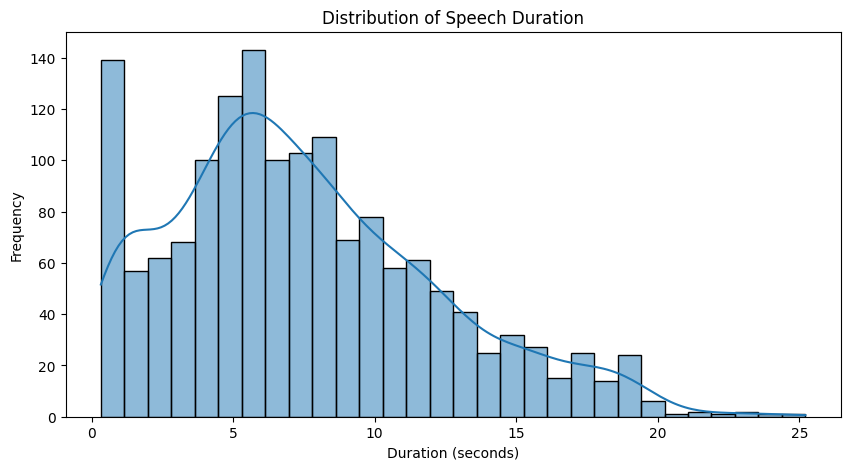

In [ ]:
# Basic statistics of the continuous variable

print("Duration statistics:")
display(df_sample["duration"].describe())

print("\nMissing values:")
print(df_sample["duration"].isna().sum())

# Visualize duration distribution
plt.figure(figsize=(10, 5))
sns.histplot(df_sample["duration"], bins=30, kde=True)

plt.title("Distribution of Speech Duration")
plt.xlabel("Duration (seconds)")
plt.ylabel("Frequency")
plt.show()

In [ ]:
# Check data quality

print("Missing values in each column:")
display(df_sample.isnull().sum())

print("\nTotal duplicate rows:")
print(df_sample.duplicated().sum())

Missing values in each column:


,0
verbatim,0
normalized,0
duration,0
scenario,0
fname,0
native_language,0
gender,0
age_group,0
native_state,0
native_district,0



Total duplicate rows:
0


In [ ]:
# Create simple text-based features

df_sample["text_length"] = df_sample["text"].str.len()
df_sample["word_count"] = df_sample["text"].str.split().str.len()

print("Text length statistics:")
display(df_sample["text_length"].describe())

print("\nWord count statistics:")
display(df_sample["word_count"].describe())

Text length statistics:


,text_length
count,1538.000000
mean,81.659948
std,54.211297
min,2.000000
25%,42.000000
50%,75.000000
75%,115.000000
max,310.000000



Word count statistics:


,word_count
count,1538.000000
mean,17.374512
std,11.743637
min,1.000000
25%,9.000000
50%,16.000000
75%,24.000000
max,70.000000


Correlation matrix:


,duration,text_length,word_count
duration,1.000000,0.933163,0.919725
text_length,0.933163,1.000000,0.984441
word_count,0.919725,0.984441,1.000000


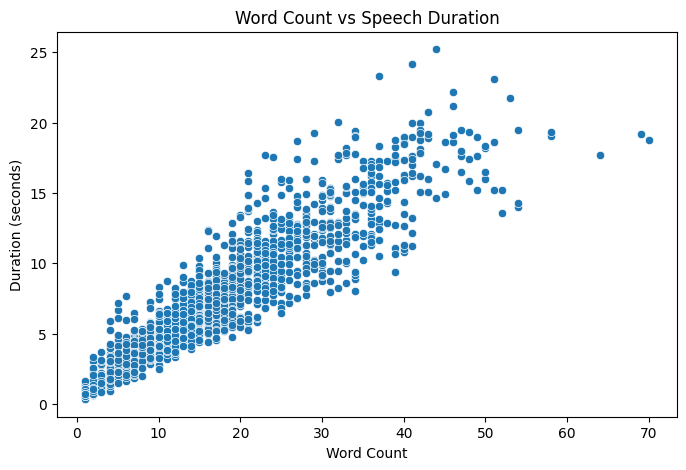

In [ ]:
# Check correlations between numerical features

numeric_features = [
    "duration",
    "text_length",
    "word_count"
]

print("Correlation matrix:")
display(df_sample[numeric_features].corr())

# Visualize relationship between word count and duration
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_sample,
    x="word_count",
    y="duration"
)

plt.title("Word Count vs Speech Duration")
plt.xlabel("Word Count")
plt.ylabel("Duration (seconds)")
plt.show()

In [ ]:
# Summary of categorical variables

categorical_columns = [
    "native_language",
    "gender",
    "age_group",
    "native_state",
    "scenario"
]

for col in categorical_columns:
    print(f"\n{col}:")
    print(f"Unique values: {df_sample[col].nunique()}")
    print(df_sample[col].value_counts())


native_language:
Unique values: 12
native_language
Nepali       359
Marathi      296
Gujarati     166
Assamese     158
Bengali      102
Kannada       83
Bodo          82
Malayalam     79
Tamil         70
Punjabi       54
Konkani       47
Dogri         42
Name: count, dtype: int64

gender:
Unique values: 2
gender
Female    835
Male      703
Name: count, dtype: int64

age_group:
Unique values: 4
age_group
18-30    695
30-45    520
45-60    228
60+       95
Name: count, dtype: int64

native_state:
Unique values: 11
native_state
West Bengal      424
Maharashtra      296
Assam            240
Gujarat          166
Tamil Nadu       122
Karnataka         83
Punjab            54
Goa               47
Jammu Kashmir     42
Meghalaya         37
Kerala            27
Name: count, dtype: int64

scenario:
Unique values: 2
scenario
Extempore    1221
Read          317
Name: count, dtype: int64


In [ ]:
# Load metadata from all LAHAJA Parquet shards

metadata_columns = [
    "verbatim",
    "normalized",
    "duration",
    "scenario",
    "fname",
    "native_language",
    "gender",
    "age_group",
    "native_state",
    "native_district",
    "sp_id",
    "text",
    "lang"
]

parquet_files = sorted(data_dir.glob("test-*.parquet"))

print("Files found:")
for file in parquet_files:
    print(file.name)

# Read metadata from each shard
df_list = []

for file in parquet_files:
    print(f"\nLoading: {file.name}")

    df = pq.read_table(
        file,
        columns=metadata_columns
    ).to_pandas()

    df_list.append(df)

    print("Rows:", len(df))

# Combine all shards
df_all = pd.concat(df_list, ignore_index=True)

print("\nFinal dataset shape:", df_all.shape)

Files found:
test-00000-of-00004.parquet
test-00001-of-00004.parquet
test-00002-of-00004.parquet
test-00003-of-00004.parquet

Loading: test-00000-of-00004.parquet
Rows: 1538

Loading: test-00001-of-00004.parquet
Rows: 1538

Loading: test-00002-of-00004.parquet
Rows: 1538

Loading: test-00003-of-00004.parquet
Rows: 1538

Final dataset shape: (6152, 13)


In [ ]:
# Create text-based numerical features

df_all["text_length"] = df_all["text"].str.len()
df_all["word_count"] = df_all["text"].str.split().str.len()

print("Dataset shape:", df_all.shape)

print("\nText length statistics:")
display(df_all["text_length"].describe())

print("\nWord count statistics:")
display(df_all["word_count"].describe())

Dataset shape: (6152, 15)

Text length statistics:


,text_length
count,6152.000000
mean,76.167100
std,54.657293
min,1.000000
25%,34.000000
50%,67.000000
75%,111.000000
max,376.000000



Word count statistics:


,word_count
count,6152.000000
mean,16.275520
std,11.865474
min,1.000000
25%,7.000000
50%,14.000000
75%,23.000000
max,86.000000


In [ ]:
# Final categorical distribution of the complete dataset

categorical_columns = [
    "native_language",
    "gender",
    "age_group",
    "native_state",
    "native_district",
    "scenario"
]

for col in categorical_columns:
    print(f"\n{'=' * 50}")
    print(f"{col}")
    print(f"Unique values: {df_all[col].nunique()}")
    print(df_all[col].value_counts())


native_language
Unique values: 19
native_language
Hindi        575
Telugu       474
Konkani      422
Bengali      418
Marathi      395
Bodo         380
Odia         374
Malayalam    365
Nepali       359
Kashmiri     320
Kannada      313
Gujarati     299
Maithili     287
Assamese     262
Punjabi      236
Dogri        219
Tamil        182
Sindhi       141
Urdu         131
Name: count, dtype: int64

gender
Unique values: 2
gender
Female    3106
Male      3046
Name: count, dtype: int64

age_group
Unique values: 4
age_group
30-45    2195
18-30    2125
45-60    1299
60+       533
Name: count, dtype: int64

native_state
Unique values: 18
native_state
West Bengal       740
Assam             642
Jammu Kashmir     544
Goa               480
Odisha            445
Gujarat           422
Maharashtra       387
Karnataka         375
Andhra Pradesh    322
Madhya Pradesh    314
Punjab            313
Kerala            313
Bihar             287
Tamil Nadu        256
Telangana         142
Rajasthan        

In [ ]:
# Final data-quality check

print("Total rows:", len(df_all))

print("\nMissing values:")
display(df_all.isnull().sum())

print("\nTotal duplicate rows:")
print(df_all.duplicated().sum())

Total rows: 6152

Missing values:


,0
verbatim,0
normalized,0
duration,0
scenario,0
fname,0
native_language,0
gender,0
age_group,0
native_state,0
native_district,0



Total duplicate rows:
0


In [ ]:
# Prepare data for the regression task

regression_features = [
    "text_length",
    "word_count",
    "gender",
    "age_group",
    "scenario",
    "native_language"
]

X_reg = df_all[regression_features].copy()
y_reg = df_all["duration"].copy()

print("Regression features:")
print(X_reg.columns.tolist())

print("\nFeature shape:", X_reg.shape)
print("Target shape:", y_reg.shape)

display(X_reg.head())

Regression features:
['text_length', 'word_count', 'gender', 'age_group', 'scenario', 'native_language']

Feature shape: (6152, 6)
Target shape: (6152,)


,text_length,word_count,gender,age_group,scenario,native_language
0,144,25,Female,18-30,Read,Marathi
1,145,29,Female,18-30,Read,Marathi
2,38,8,Female,18-30,Read,Marathi
3,47,8,Female,18-30,Read,Marathi
4,43,11,Female,18-30,Read,Marathi


In [ ]:
from sklearn.model_selection import train_test_split

# Split the regression dataset
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_reg_train.shape[0])
print("Testing samples:", X_reg_test.shape[0])

Training samples: 4921
Testing samples: 1231


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Define feature types
numeric_features = [
    "text_length",
    "word_count"
]

categorical_features = [
    "gender",
    "age_group",
    "scenario",
    "native_language"
]

# Create preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [ ]:
# Fit preprocessing only on the training data
X_reg_train_processed = preprocessor.fit_transform(X_reg_train)

# Transform the test data using the same fitted preprocessor
X_reg_test_processed = preprocessor.transform(X_reg_test)

print("Processed training shape:", X_reg_train_processed.shape)
print("Processed testing shape:", X_reg_test_processed.shape)

Processed training shape: (4921, 29)
Processed testing shape: (1231, 29)


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Least Squares Linear Regression
linear_model = LinearRegression()

linear_model.fit(X_reg_train_processed, y_reg_train)

# Predictions
y_reg_pred = linear_model.predict(X_reg_test_processed)

# Evaluation
mse = mean_squared_error(y_reg_test, y_reg_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_reg_test, y_reg_pred)
r2 = r2_score(y_reg_test, y_reg_pred)

print("Least Squares Linear Regression Results")
print("---------------------------------------")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"MAE  : {mae:.4f}")
print(f"R²   : {r2:.4f}")

Least Squares Linear Regression Results
---------------------------------------
MSE  : 2.6720
RMSE : 1.6346
MAE  : 1.1859
R²   : 0.8838


In [ ]:
from sklearn.linear_model import HuberRegressor

# Robust Linear Regression
robust_model = HuberRegressor()

robust_model.fit(X_reg_train_processed, y_reg_train)

# Predictions
y_robust_pred = robust_model.predict(X_reg_test_processed)

# Evaluation
mse_robust = mean_squared_error(y_reg_test, y_robust_pred)
rmse_robust = np.sqrt(mse_robust)
mae_robust = mean_absolute_error(y_reg_test, y_robust_pred)
r2_robust = r2_score(y_reg_test, y_robust_pred)

print("Robust Linear Regression (Huber) Results")
print("-----------------------------------------")
print(f"MSE  : {mse_robust:.4f}")
print(f"RMSE : {rmse_robust:.4f}")
print(f"MAE  : {mae_robust:.4f}")
print(f"R²   : {r2_robust:.4f}")

Robust Linear Regression (Huber) Results
-----------------------------------------
MSE  : 2.7445
RMSE : 1.6567
MAE  : 1.1566
R²   : 0.8807


In [ ]:
from sklearn.linear_model import Ridge

# Ridge Regression
ridge_model = Ridge(alpha=1.0)

ridge_model.fit(X_reg_train_processed, y_reg_train)

# Predictions
y_ridge_pred = ridge_model.predict(X_reg_test_processed)

# Evaluation
mse_ridge = mean_squared_error(y_reg_test, y_ridge_pred)
rmse_ridge = np.sqrt(mse_ridge)
mae_ridge = mean_absolute_error(y_reg_test, y_ridge_pred)
r2_ridge = r2_score(y_reg_test, y_ridge_pred)

print("Ridge Regression Results")
print("------------------------")
print(f"MSE  : {mse_ridge:.4f}")
print(f"RMSE : {rmse_ridge:.4f}")
print(f"MAE  : {mae_ridge:.4f}")
print(f"R²   : {r2_ridge:.4f}")

Ridge Regression Results
------------------------
MSE  : 2.6718
RMSE : 1.6346
MAE  : 1.1859
R²   : 0.8839


In [ ]:
from sklearn.linear_model import BayesianRidge

# Convert sparse matrices to dense
X_reg_train_dense = X_reg_train_processed.toarray()
X_reg_test_dense = X_reg_test_processed.toarray()

# Bayesian Linear Regression
bayesian_model = BayesianRidge()

bayesian_model.fit(X_reg_train_dense, y_reg_train)

# Predictions
y_bayesian_pred = bayesian_model.predict(X_reg_test_dense)

# Evaluation
mse_bayesian = mean_squared_error(y_reg_test, y_bayesian_pred)
rmse_bayesian = np.sqrt(mse_bayesian)
mae_bayesian = mean_absolute_error(y_reg_test, y_bayesian_pred)
r2_bayesian = r2_score(y_reg_test, y_bayesian_pred)

print("Bayesian Linear Regression Results")
print("----------------------------------")
print(f"MSE  : {mse_bayesian:.4f}")
print(f"RMSE : {rmse_bayesian:.4f}")
print(f"MAE  : {mae_bayesian:.4f}")
print(f"R²   : {r2_bayesian:.4f}")

Bayesian Linear Regression Results
----------------------------------
MSE  : 2.6708
RMSE : 1.6343
MAE  : 1.1857
R²   : 0.8839


In [ ]:
# Compare all regression models

model_comparison = pd.DataFrame({
    "Model": [
        "Least Squares",
        "Robust Linear Regression",
        "Ridge Regression",
        "Bayesian Linear Regression"
    ],
    "MSE": [
        mse,
        mse_robust,
        mse_ridge,
        mse_bayesian
    ],
    "RMSE": [
        rmse,
        rmse_robust,
        rmse_ridge,
        rmse_bayesian
    ],
    "MAE": [
        mae,
        mae_robust,
        mae_ridge,
        mae_bayesian
    ],
    "R²": [
        r2,
        r2_robust,
        r2_ridge,
        r2_bayesian
    ]
})

display(model_comparison.round(4))

,Model,MSE,RMSE,MAE,R²
0,Least Squares,2.6720,1.6346,1.1859,0.8838
1,Robust Linear Regression,2.7445,1.6567,1.1566,0.8807
2,Ridge Regression,2.6718,1.6346,1.1859,0.8839
3,Bayesian Linear Regression,2.6708,1.6343,1.1857,0.8839


In [ ]:
import plotly.express as px

fig = px.bar(
    model_comparison,
    x="Model",
    y="R²",
    text="R²",
    title="Interactive R² Comparison of Regression Models",
    hover_data=["MSE", "RMSE", "MAE"]
)

fig.update_traces(
    texttemplate="%{text:.4f}",
    textposition="outside"
)

fig.update_layout(
    yaxis_title="R² Score",
    xaxis_title="Model",
    yaxis_range=[0, 1],
    template="plotly_dark"
)

fig.show()

In [ ]:
import plotly.express as px

correlation_matrix = df_all[
    ["duration", "text_length", "word_count"]
].corr()

fig = px.imshow(
    correlation_matrix,
    text_auto=".2f",
    title="Interactive Correlation Heatmap"
)

fig.update_layout(template="plotly_dark")

fig.show()

In [ ]:
fig = px.scatter(
    df_all,
    x="word_count",
    y="duration",
    title="Word Count vs Speech Duration",
    labels={
        "word_count": "Word Count",
        "duration": "Duration (seconds)"
    },
    hover_data=[
        "text_length",
        "native_language",
        "gender",
        "native_state"
    ]
)

fig.update_layout(template="plotly_dark")

fig.show()

In [ ]:
fig = px.scatter(
    df_all,
    x="word_count",
    y="duration",
    title="Word Count vs Speech Duration",
    labels={
        "word_count": "Word Count",
        "duration": "Duration (seconds)"
    },
    hover_data=[
        "text_length",
        "native_language",
        "gender",
        "native_state"
    ]
)

fig.update_layout(template="plotly_dark")

fig.show()

In [ ]:
fig = px.box(
    df_all,
    x="scenario",
    y="duration",
    points="outliers",
    title="Speech Duration by Scenario",
    labels={
        "scenario": "Speech Scenario",
        "duration": "Duration (seconds)"
    }
)

fig.update_layout(template="plotly_dark")

fig.show()

In [ ]:
fig = px.box(
    df_all,
    x="gender",
    y="duration",
    points="outliers",
    title="Speech Duration by Gender",
    labels={
        "gender": "Gender",
        "duration": "Duration (seconds)"
    }
)

fig.update_layout(template="plotly_dark")

fig.show()

In [ ]:
# Prepare data for classification

classification_features = [
    "text_length",
    "word_count",
    "gender",
    "age_group",
    "scenario"
]

X_cls = df_all[classification_features].copy()
y_cls = df_all["native_language"].copy()

print("Classification features:")
print(X_cls.columns.tolist())

print("\nNumber of classes:", y_cls.nunique())

print("\nClass distribution:")
print(y_cls.value_counts())

print("\nFeature shape:", X_cls.shape)
print("Target shape:", y_cls.shape)

Classification features:
['text_length', 'word_count', 'gender', 'age_group', 'scenario']

Number of classes: 19

Class distribution:
native_language
Hindi        575
Telugu       474
Konkani      422
Bengali      418
Marathi      395
Bodo         380
Odia         374
Malayalam    365
Nepali       359
Kashmiri     320
Kannada      313
Gujarati     299
Maithili     287
Assamese     262
Punjabi      236
Dogri        219
Tamil        182
Sindhi       141
Urdu         131
Name: count, dtype: int64

Feature shape: (6152, 5)
Target shape: (6152,)


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Train-test split
X_cls_train, X_cls_test, y_cls_train, y_cls_test = train_test_split(
    X_cls,
    y_cls,
    test_size=0.2,
    random_state=42,
    stratify=y_cls
)

print("Training samples:", X_cls_train.shape[0])
print("Testing samples:", X_cls_test.shape[0])

# Define feature types
numeric_cls_features = [
    "text_length",
    "word_count"
]

categorical_cls_features = [
    "gender",
    "age_group",
    "scenario"
]

# Preprocessing
cls_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cls_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cls_features)
    ]
)

# Fit only on training data
X_cls_train_processed = cls_preprocessor.fit_transform(X_cls_train)

# Transform test data
X_cls_test_processed = cls_preprocessor.transform(X_cls_test)

print("\nProcessed training shape:", X_cls_train_processed.shape)
print("Processed testing shape:", X_cls_test_processed.shape)

Training samples: 4921
Testing samples: 1231

Processed training shape: (4921, 10)
Processed testing shape: (1231, 10)


In [ ]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, classification_report

# Linear Discriminant Analysis
lda_model = LinearDiscriminantAnalysis()

# Convert to dense only if the data is sparse
X_cls_train_dense = (
    X_cls_train_processed.toarray()
    if hasattr(X_cls_train_processed, "toarray")
    else X_cls_train_processed
)

X_cls_test_dense = (
    X_cls_test_processed.toarray()
    if hasattr(X_cls_test_processed, "toarray")
    else X_cls_test_processed
)

lda_model.fit(X_cls_train_dense, y_cls_train)

# Predictions
y_lda_pred = lda_model.predict(X_cls_test_dense)

# Evaluation
lda_accuracy = accuracy_score(y_cls_test, y_lda_pred)

print("Linear Discriminant Analysis Results")
print("------------------------------------")
print(f"Accuracy: {lda_accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(y_cls_test, y_lda_pred))

Linear Discriminant Analysis Results
------------------------------------
Accuracy: 0.1625

Classification Report:
              precision    recall  f1-score   support

    Assamese       0.00      0.00      0.00        52
     Bengali       0.00      0.00      0.00        84
        Bodo       0.17      0.46      0.25        76
       Dogri       0.29      0.09      0.14        44
    Gujarati       0.34      0.50      0.41        60
       Hindi       0.00      0.00      0.00       115
     Kannada       0.12      0.60      0.21        63
    Kashmiri       0.18      0.56      0.28        64
     Konkani       0.50      0.01      0.02        85
    Maithili       0.09      0.16      0.11        57
   Malayalam       0.16      0.45      0.24        73
     Marathi       0.26      0.09      0.13        79
      Nepali       0.00      0.00      0.00        72
        Odia       0.16      0.09      0.12        75
     Punjabi       0.00      0.00      0.00        47
      Sindhi       0

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.



In [ ]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report

# Create Gaussian Naive Bayes model
gnb_model = GaussianNB()

# Train the model
gnb_model.fit(X_cls_train_dense, y_cls_train)

# Make predictions
y_gnb_pred = gnb_model.predict(X_cls_test_dense)

# Evaluate
gnb_accuracy = accuracy_score(y_cls_test, y_gnb_pred)

print("Gaussian Naive Bayes Results")
print("--------------------------------")
print(f"Accuracy: {gnb_accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_cls_test,
    y_gnb_pred,
    zero_division=0
))

Gaussian Naive Bayes Results
--------------------------------
Accuracy: 0.0959

Classification Report:
              precision    recall  f1-score   support

    Assamese       0.07      0.02      0.03        52
     Bengali       0.00      0.00      0.00        84
        Bodo       0.19      0.41      0.26        76
       Dogri       0.33      0.02      0.04        44
    Gujarati       0.30      0.50      0.38        60
       Hindi       0.00      0.00      0.00       115
     Kannada       0.03      0.17      0.04        63
    Kashmiri       1.00      0.02      0.03        64
     Konkani       0.00      0.00      0.00        85
    Maithili       0.00      0.00      0.00        57
   Malayalam       0.00      0.00      0.00        73
     Marathi       0.33      0.09      0.14        79
      Nepali       0.00      0.00      0.00        72
        Odia       0.00      0.00      0.00        75
     Punjabi       0.50      0.02      0.04        47
      Sindhi       0.00      0.0

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Create Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

# Train the model
logistic_model.fit(X_cls_train_processed, y_cls_train)

# Make predictions
y_logistic_pred = logistic_model.predict(X_cls_test_processed)

# Evaluate
logistic_accuracy = accuracy_score(y_cls_test, y_logistic_pred)

print("Logistic Regression Results")
print("--------------------------------")
print(f"Accuracy: {logistic_accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_cls_test,
    y_logistic_pred,
    zero_division=0
))

Logistic Regression Results
--------------------------------
Accuracy: 0.1787

Classification Report:
              precision    recall  f1-score   support

    Assamese       0.08      0.02      0.03        52
     Bengali       0.00      0.00      0.00        84
        Bodo       0.19      0.41      0.26        76
       Dogri       0.57      0.09      0.16        44
    Gujarati       0.24      0.42      0.30        60
       Hindi       0.18      0.27      0.22       115
     Kannada       0.15      0.40      0.22        63
    Kashmiri       0.18      0.55      0.27        64
     Konkani       0.18      0.04      0.06        85
    Maithili       0.10      0.14      0.11        57
   Malayalam       0.18      0.45      0.26        73
     Marathi       0.28      0.10      0.15        79
      Nepali       0.09      0.01      0.02        72
        Odia       0.14      0.09      0.11        75
     Punjabi       0.00      0.00      0.00        47
      Sindhi       0.00      0.00

In [ ]:
import numpy as np
from scipy.optimize import minimize
from scipy.special import expit

# Hindi vs. all other languages
y_binary = (y_cls_train == "Hindi").astype(int)

# Convert to dense if necessary
X_laplace = (
    X_cls_train_processed.toarray()
    if hasattr(X_cls_train_processed, "toarray")
    else X_cls_train_processed
)

# Add intercept
X_laplace = np.column_stack([
    np.ones(X_laplace.shape[0]),
    X_laplace
])

# Negative log-posterior
def negative_log_posterior(w):
    z = X_laplace @ w

    # Stable log-likelihood
    log_likelihood = np.sum(
        y_binary * np.logaddexp(0, -z) * -1 +
        (1 - y_binary) * np.logaddexp(0, z) * -1
    )

    # Gaussian prior
    prior = 0.5 * np.sum(w ** 2)

    return -log_likelihood + prior


# Start from zero weights
initial_weights = np.zeros(X_laplace.shape[1])

# MAP optimization
map_result = minimize(
    negative_log_posterior,
    initial_weights,
    method="L-BFGS-B",
    options={
        "maxiter": 2000,
        "ftol": 1e-9
    }
)

map_weights = map_result.x

print("Laplace Approximation")
print("--------------------------------")
print(f"Optimization successful: {map_result.success}")
print(f"Message: {map_result.message}")
print(f"MAP objective value: {map_result.fun:.4f}")
print(f"Number of parameters: {len(map_weights)}")

Laplace Approximation
--------------------------------
Optimization successful: True
Message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
MAP objective value: 1385.7298
Number of parameters: 11


In [ ]:
# Calculate probabilities at the MAP estimate
z_map = X_laplace @ map_weights
p_map = expit(z_map)

# Weight matrix for the Hessian
W = p_map * (1 - p_map)

# Hessian of the negative log-posterior
H = X_laplace.T @ (W[:, None] * X_laplace) + np.eye(X_laplace.shape[1])

# Laplace covariance approximation
laplace_covariance = np.linalg.inv(H)

print("Laplace Approximation Results")
print("--------------------------------")
print(f"MAP parameters: {len(map_weights)}")
print(f"Covariance matrix shape: {laplace_covariance.shape}")

# Check positive definiteness
eigenvalues = np.linalg.eigvalsh(laplace_covariance)

print(f"Minimum covariance eigenvalue: {eigenvalues.min():.6f}")
print(f"Maximum covariance eigenvalue: {eigenvalues.max():.6f}")

Laplace Approximation Results
--------------------------------
MAP parameters: 11
Covariance matrix shape: (11, 11)
Minimum covariance eigenvalue: 0.000998
Maximum covariance eigenvalue: 1.000000


In [ ]:
# Prepare test data
X_laplace_test = (
    X_cls_test_processed.toarray()
    if hasattr(X_cls_test_processed, "toarray")
    else X_cls_test_processed
)

# Add intercept
X_laplace_test = np.column_stack([
    np.ones(X_laplace_test.shape[0]),
    X_laplace_test
])

# Predictive probabilities using the MAP estimate
test_logits = X_laplace_test @ map_weights
test_probabilities = expit(test_logits)

# Convert probabilities to binary predictions
y_bayes_pred = (test_probabilities >= 0.5).astype(int)

# Actual binary test labels
y_binary_test = (y_cls_test == "Hindi").astype(int)

# Evaluate
from sklearn.metrics import accuracy_score, classification_report

bayesian_accuracy = accuracy_score(
    y_binary_test,
    y_bayes_pred
)

print("Bayesian Logistic Regression Results")
print("--------------------------------")
print(f"Accuracy: {bayesian_accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_binary_test,
    y_bayes_pred,
    target_names=["Other Languages", "Hindi"],
    zero_division=0
))

Bayesian Logistic Regression Results
--------------------------------
Accuracy: 0.9066

Classification Report:
                 precision    recall  f1-score   support

Other Languages       0.91      1.00      0.95      1116
          Hindi       0.00      0.00      0.00       115

       accuracy                           0.91      1231
      macro avg       0.45      0.50      0.48      1231
   weighted avg       0.82      0.91      0.86      1231



In [ ]:
from sklearn.metrics.pairwise import rbf_kernel

# Use a small subset for visualization/computation
X_kernel_sample = (
    X_cls_train_processed[:200].toarray()
    if hasattr(X_cls_train_processed, "toarray")
    else X_cls_train_processed[:200]
)

# Calculate RBF kernel matrix
K_rbf = rbf_kernel(
    X_kernel_sample,
    X_kernel_sample,
    gamma=0.5
)

print("RBF Kernel Function")
print("--------------------------------")
print(f"Kernel matrix shape: {K_rbf.shape}")
print(f"Minimum kernel value: {K_rbf.min():.4f}")
print(f"Maximum kernel value: {K_rbf.max():.4f}")
print(f"Diagonal value example: {K_rbf[0, 0]:.4f}")

RBF Kernel Function
--------------------------------
Kernel matrix shape: (200, 200)
Minimum kernel value: 0.0000
Maximum kernel value: 1.0000
Diagonal value example: 1.0000


In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# Create SVM with RBF kernel
svm_rbf = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    random_state=42
)

# Train the model
svm_rbf.fit(X_cls_train_processed, y_cls_train)

# Make predictions
y_svm_rbf_pred = svm_rbf.predict(X_cls_test_processed)

# Evaluate
svm_rbf_accuracy = accuracy_score(
    y_cls_test,
    y_svm_rbf_pred
)

print("SVM with RBF Kernel Results")
print("--------------------------------")
print(f"Accuracy: {svm_rbf_accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_cls_test,
    y_svm_rbf_pred,
    zero_division=0
))

SVM with RBF Kernel Results
--------------------------------
Accuracy: 0.2210

Classification Report:
              precision    recall  f1-score   support

    Assamese       0.00      0.00      0.00        52
     Bengali       0.11      0.13      0.12        84
        Bodo       0.19      0.33      0.24        76
       Dogri       1.00      0.05      0.09        44
    Gujarati       0.59      0.40      0.48        60
       Hindi       0.23      0.38      0.29       115
     Kannada       0.18      0.14      0.16        63
    Kashmiri       0.21      0.39      0.27        64
     Konkani       0.00      0.00      0.00        85
    Maithili       0.12      0.14      0.13        57
   Malayalam       0.24      0.41      0.30        73
     Marathi       0.24      0.32      0.27        79
      Nepali       0.00      0.00      0.00        72
        Odia       0.30      0.32      0.31        75
     Punjabi       1.00      0.02      0.04        47
      Sindhi       0.00      0.00

In [ ]:
classification_comparison = pd.DataFrame({
    "Model": [
        "Linear Discriminant Analysis",
        "Gaussian Naive Bayes",
        "Logistic Regression",
        "SVM (RBF Kernel)"
    ],
    "Accuracy": [
        lda_accuracy,
        gnb_accuracy,
        logistic_accuracy,
        svm_rbf_accuracy
    ]
})

display(classification_comparison.round(4))

,Model,Accuracy
0,Linear Discriminant Analysis,0.1625
1,Gaussian Naive Bayes,0.0959
2,Logistic Regression,0.1787
3,SVM (RBF Kernel),0.2210


In [ ]:
import plotly.express as px

fig = px.bar(
    classification_comparison,
    x="Model",
    y="Accuracy",
    title="Classification Model Accuracy Comparison",
    text="Accuracy",
    hover_data=["Accuracy"]
)

fig.update_traces(
    texttemplate="%{text:.2%}",
    textposition="outside"
)

fig.update_layout(
    template="plotly_dark",
    yaxis_title="Accuracy",
    xaxis_title="Model",
    yaxis=dict(range=[0, 0.25])
)

fig.show()

In [ ]:
from sklearn.metrics import confusion_matrix
import plotly.figure_factory as ff

# Generate confusion matrix
cm = confusion_matrix(
    y_cls_test,
    y_svm_rbf_pred,
    labels=sorted(y_cls_test.unique())
)

labels = sorted(y_cls_test.unique())

fig = ff.create_annotated_heatmap(
    z=cm,
    x=labels,
    y=labels,
    colorscale="Viridis",
    showscale=True
)

fig.update_layout(
    template="plotly_dark",
    title="SVM (RBF) Confusion Matrix",
    xaxis_title="Predicted Language",
    yaxis_title="Actual Language",
    width=1000,
    height=900
)

fig.show()

In [ ]:
from sklearn.metrics import precision_recall_fscore_support

precision, recall, f1, support = precision_recall_fscore_support(
    y_cls_test,
    y_svm_rbf_pred,
    labels=labels,
    zero_division=0
)

svm_classification_report = pd.DataFrame({
    "Language": labels,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1,
    "Support": support
})

display(
    svm_classification_report.round(4)
)

,Language,Precision,Recall,F1-Score,Support
0,Assamese,0.0000,0.0000,0.0000,52
1,Bengali,0.1122,0.1310,0.1209,84
2,Bodo,0.1866,0.3289,0.2381,76
3,Dogri,1.0000,0.0455,0.0870,44
4,Gujarati,0.5854,0.4000,0.4752,60
5,Hindi,0.2328,0.3826,0.2895,115
6,Kannada,0.1765,0.1429,0.1579,63
7,Kashmiri,0.2083,0.3906,0.2717,64
8,Konkani,0.0000,0.0000,0.0000,85
9,Maithili,0.1212,0.1404,0.1301,57


In [ ]:
# Generate predictions for all regression models

y_pred = linear_model.predict(X_reg_test_processed)

y_pred_robust = robust_model.predict(X_reg_test_processed)

y_pred_ridge = ridge_model.predict(X_reg_test_processed)

y_pred_bayesian = bayesian_model.predict(X_reg_test_dense)

In [ ]:
import plotly.graph_objects as go

fig = go.Figure()

# Actual values
fig.add_trace(
    go.Scatter(
        x=y_reg_test,
        y=y_reg_test,
        mode="lines",
        name="Ideal Prediction"
    )
)

# Least Squares
fig.add_trace(
    go.Scatter(
        x=y_reg_test,
        y=y_pred,
        mode="markers",
        name="Least Squares",
        opacity=0.6
    )
)

# Robust Linear Regression
fig.add_trace(
    go.Scatter(
        x=y_reg_test,
        y=y_pred_robust,
        mode="markers",
        name="Robust Linear Regression",
        opacity=0.6
    )
)

# Ridge Regression
fig.add_trace(
    go.Scatter(
        x=y_reg_test,
        y=y_pred_ridge,
        mode="markers",
        name="Ridge Regression",
        opacity=0.6
    )
)

# Bayesian Linear Regression
fig.add_trace(
    go.Scatter(
        x=y_reg_test,
        y=y_pred_bayesian,
        mode="markers",
        name="Bayesian Linear Regression",
        opacity=0.6
    )
)

fig.update_layout(
    template="plotly_dark",
    title="Regression Models: Actual vs Predicted",
    xaxis_title="Actual Duration",
    yaxis_title="Predicted Duration"
)

fig.show()

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import plotly.graph_objects as go

# ROC curve
fpr, tpr, thresholds = roc_curve(
    y_binary_test,
    test_probabilities
)

auc_score = roc_auc_score(
    y_binary_test,
    test_probabilities
)

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=fpr,
        y=tpr,
        mode="lines",
        name=f"Bayesian Logistic Regression (AUC = {auc_score:.3f})"
    )
)

# Random classifier reference line
fig.add_trace(
    go.Scatter(
        x=[0, 1],
        y=[0, 1],
        mode="lines",
        name="Random Classifier",
        line=dict(dash="dash")
    )
)

fig.update_layout(
    template="plotly_dark",
    title="ROC Curve - Bayesian Logistic Regression",
    xaxis_title="False Positive Rate",
    yaxis_title="True Positive Rate",
    xaxis=dict(range=[0, 1]),
    yaxis=dict(range=[0, 1])
)

fig.show()

print(f"ROC-AUC Score: {auc_score:.4f}")

ROC-AUC Score: 0.6871
